### Checkpoint 1

Implement your algorithm to process and annotate the traces of the 20 unipolar electrogram signals, identifying focal activity based on activation patterns and signal morphology.

The algorithm must return the following outputs:

1. **Activation Annotations**: for each of the 20 signals, generate a list of activation times. These activation times correspond to the local minima of the first derivative of the signal, indicating the moments of depolarization at each electrode.
2. **Focal proximity**: assign a score of 1 to the sensor closest to the focal activity and 0 to all others. If the focal activity is within two sensors (up to a specified tolerance), assign 0.5 to each of the two sensors.
This output should be guided by signal morphology: focal activity is expected to correspond to a QS morphology (i.e., a single dominant negative deflection).

Provide your algorithm's implementation in this notebook to annotate the traces of the 20 unipolar signals and identify focal activity based on activation patterns and waveform morphology.



In [2]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import argrelextrema, savgol_filter

In [3]:
# load data
signals = np.load('checkpoint1dataset.npy')

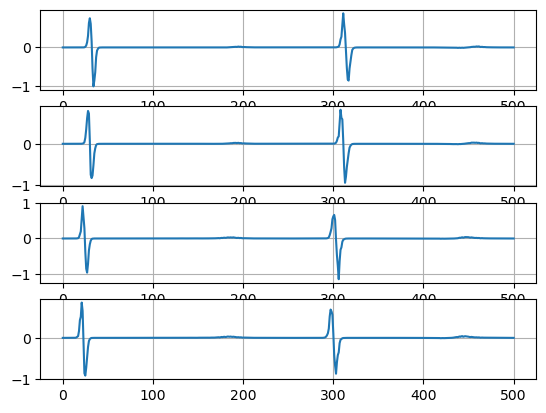

In [4]:
# select event to be display
ind_event = 0

# select a spline (options: 0,1,2,3,4)
ind_spline = 3

# plot signals

plt.figure(1+ind_spline)
countEL = 1
for indS in np.arange(ind_spline*4,(ind_spline+1)*4,1):
    plt.subplot(4,1,countEL)
            
    plt.plot(signals[ind_event,indS,:])
    plt.grid(True)

    countEL = countEL + 1

plt.show()

signals_event = signals[ind_event,:,:]

In [4]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy.signal import savgol_filter, argrelextrema

# # --- CONFIGURAZIONE ---
# ev_test = 3
# spline_sensors = [8, 9, 10, 5] 
# window_length = 15
# poly_order = 3
# min_dist = 100 

# # Pre-processing (Savgol è essenziale per l'Onset)
# signals_filtered = np.zeros_like(signals)
# for ev in range(signals.shape[0]):
#     for sens in range(signals.shape[1]):
#         signals_filtered[ev, sens, :] = savgol_filter(signals[ev, sens, :], window_length, poly_order)

# # --- PLOTTING CON ANALISI ONSET ---
# n_sens = len(spline_sensors)
# fig, axs = plt.subplots(2, n_sens, figsize=(4 * n_sens, 9), sharex=True)

# if n_sens == 1: axs = axs.reshape(2, 1)

# for i, sens_idx in enumerate(spline_sensors):
#     sig_filt = signals_filtered[ev_test, sens_idx, :]
#     ds_filt = np.diff(sig_filt)
    
#     # 1. Trova i picchi di attivazione (minimi derivata)
#     min_indices = argrelextrema(ds_filt, np.less)[0]
#     selected_peaks = []
#     if len(min_indices) > 0:
#         depths = ds_filt[min_indices]
#         candidates = min_indices[np.argsort(depths)]
#         for c in candidates:
#             if len(selected_peaks) == 0 or all(abs(c - p) > min_dist for p in selected_peaks):
#                 selected_peaks.append(c)
#             if len(selected_peaks) == 2: break
#     selected_peaks.sort()

#     # 2. Calcolo dell'Onset (Distacco dalla baseline)
#     onsets = []
#     for p in selected_peaks:
#         # Analizziamo una finestra di 50 campioni prima del picco
#         search_back = 50
#         start_win = max(0, p - search_back)
#         window = sig_filt[start_win : p]
        
#         # Calcoliamo la baseline e una soglia di distacco dinamica (noise floor)
#         # Usiamo i primi 10 campioni della finestra come riferimento di "quiete"
#         local_baseline = np.mean(sig_filt[start_win : start_win + 10])
#         noise_std = np.std(sig_filt[start_win : start_win + 10])
#         threshold = max(3 * noise_std, 0.02 * (np.max(sig_filt) - np.min(sig_filt)))
        
#         # Torniamo indietro dal picco p finché il segnale non rientra nella soglia
#         onset_idx = p
#         for k in range(p, start_win, -1):
#             if abs(sig_filt[k] - local_baseline) < threshold:
#                 onset_idx = k
#                 break
#         onsets.append(onset_idx)

#     # --- RIGA 1: SEGNALE + ONSET ---
#     axs[0, i].plot(sig_filt, color='blue', linewidth=1.5, label='Filt')
#     for idx_o in onsets:
#         # Cerchio verde sul punto di distacco
#         axs[0, i].plot(idx_o, sig_filt[idx_o], 'go', markersize=10, markeredgecolor='black', label='Onset' if idx_o == onsets[0] else "")
#         # Linea verticale per confronto temporale
#         axs[0, i].axvline(x=idx_o, color='green', linestyle='--', alpha=0.6)
#         # Annotazione del tempo di onset
#         axs[0, i].text(idx_o, sig_filt[idx_o] + 0.1, f'T:{idx_o}', color='green', fontweight='bold', ha='center')

#     axs[0, i].set_title(f'Sensore {sens_idx}', fontsize=12, fontweight='bold')
#     axs[0, i].grid(True, alpha=0.2)
#     if i == 0: axs[0, i].legend()

#     # --- RIGA 2: DERIVATA ---
#     axs[1, i].plot(ds_filt, color='red', linewidth=1)
#     for p in selected_peaks:
#         axs[1, i].plot(p, ds_filt[p], 'ro')
#         axs[1, i].text(p, ds_filt[p] - 0.05, f'Act:{p}', color='red', fontsize=8, ha='center')
    
#     axs[1, i].set_title('Derivata (Pendenza)', fontsize=10)
#     axs[1, i].grid(True, alpha=0.2)

# plt.suptitle(f'Analisi Onset vs Activation - Evento {ev_test}\nIl cerchio verde indica il primo distacco dalla baseline (indipendentemente dalla R o S)', 
#              fontsize=14, fontweight='bold', y=0.98)
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()

In [5]:
import numpy as np
from scipy.signal import argrelextrema, savgol_filter

def GroupSolutionCP1(signals_event):
    # --- 1. PRE-PROCESSING (Filtraggio) ---
    # Puliamo il segnale per evitare che il rumore crei falsi minimi nella derivata
    # window_length=11 è un buon compromesso per segnali a 1kHz
    sig_filtered = savgol_filter(signals_event, window_length=11, polyorder=3, axis=1)
    
    n_sensors = sig_filtered.shape[0]
    timings = []
    min_dist = 100 
    time_tol = 4
    
    act_times = [[], []] 
    qs_flags = [[], []]

    for i in range(n_sensors):
        # --- 2. CALCOLO DERIVATA CON NP.GRADIENT ---
        # np.gradient è più preciso di np.diff perché usa lo schema alle differenze centrali
        # e mantiene la stessa lunghezza del segnale originale
        ds = np.gradient(sig_filtered[i, :])
        
        # Identificazione dei minimi locali della derivata (punti di massima pendenza negativa)
        min_indices = argrelextrema(ds, np.less)[0]
        
        selected = []
        qs_status = [False, False]
        
        if len(min_indices) > 0:
            # Ordiniamo i minimi per profondità
            depths = ds[min_indices]
            sorted_args = np.argsort(depths)
            candidates = min_indices[sorted_args]
            
            for idx in candidates:
                if len(selected) == 0:
                    selected.append(idx)
                elif len(selected) == 1:
                    if abs(idx - selected[0]) >= min_dist:
                        selected.append(idx)
                        break
            
            selected.sort()
            
            # --- 3. ANALISI MORFOLOGICA (QS Check) ---
            for j, val in enumerate(selected):
                window_start = max(0, val - 30)
                window_end = min(sig_filtered.shape[1], val + 30)
                
                # Usiamo il segnale filtrato anche per il calcolo della baseline e dei picchi
                baseline = np.mean(sig_filtered[i, window_start : window_start + 5])
                max_pos = np.max(sig_filtered[i, window_start : val]) - baseline
                max_neg = np.min(sig_filtered[i, val : window_end]) - baseline
                
                if max_pos < 0.1 * abs(max_neg):
                    qs_status[j] = True

        # Formattazione output timings
        row_time = [None, None]
        for j in range(len(selected)):
            row_time[j] = int(selected[j])
        
        row_final = [t if t is not None else np.nan for t in row_time]
        timings.append(row_final)

        for j in range(2):
            t_val = row_final[j] if not np.isnan(row_final[j]) else np.inf
            act_times[j].append(t_val)
            qs_flags[j].append(qs_status[j])

    # --- 4. CALCOLO LS (PROSSIMITÀ FOCALE) ---
    LS_array = np.zeros((n_sensors, 2))

    for j in range(2):
        times = np.array(act_times[j])
        flags = np.array(qs_flags[j])
        
        if np.any(np.isfinite(times)):
            min_t = np.min(times)
            focus_idxs = [idx for idx, t in enumerate(times) if t <= min_t + time_tol]
            qs_candidates = [idx for idx in focus_idxs if flags[idx]]
            
            # Logica di assegnazione prioritaria alle morfologie QS
            if qs_candidates:
                qs_candidates.sort(key=lambda x: times[x])
                if len(qs_candidates) == 1:
                    LS_array[qs_candidates[0], j] = 1.0
                else:
                    t0, t1 = times[qs_candidates[0]], times[qs_candidates[1]]
                    if abs(t1 - t0) <= time_tol:
                        LS_array[qs_candidates[0], j], LS_array[qs_candidates[1], j] = 0.5, 0.5
                    else:
                        LS_array[qs_candidates[0], j] = 1.0
            else:
                # Fallback: se nessuna QS è presente, premiamo i più veloci
                if focus_idxs:
                    focus_idxs.sort(key=lambda x: times[x])
                    if len(focus_idxs) == 1:
                        LS_array[focus_idxs[0], j] = 1.0
                    else:
                        t0, t1 = times[focus_idxs[0]], times[focus_idxs[1]]
                        if abs(t1 - t0) <= time_tol:
                            LS_array[focus_idxs[0], j], LS_array[focus_idxs[1], j] = 0.5, 0.5
                        else:
                            LS_array[focus_idxs[0], j] = 1.0

    return timings, LS_array.tolist()

In [6]:
# test it

timings_event, LS_event = GroupSolutionCP1(signals_event)

print(timings_event)
print("LS_event", LS_event)

[[17, 272], [16, 273], [15, 283], [16, 286], [33, 295], [31, 294], [25, 291], [23, 291], [39, 312], [36, 310], [29, 302], [26, 299], [32, 314], [30, 311], [24, 303], [23, 300], [16, 300], [14, 298], [14, 294], [15, 294]]
LS_event [[0.0, 1.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.5, 0.0], [0.5, 0.0], [0.0, 0.0]]


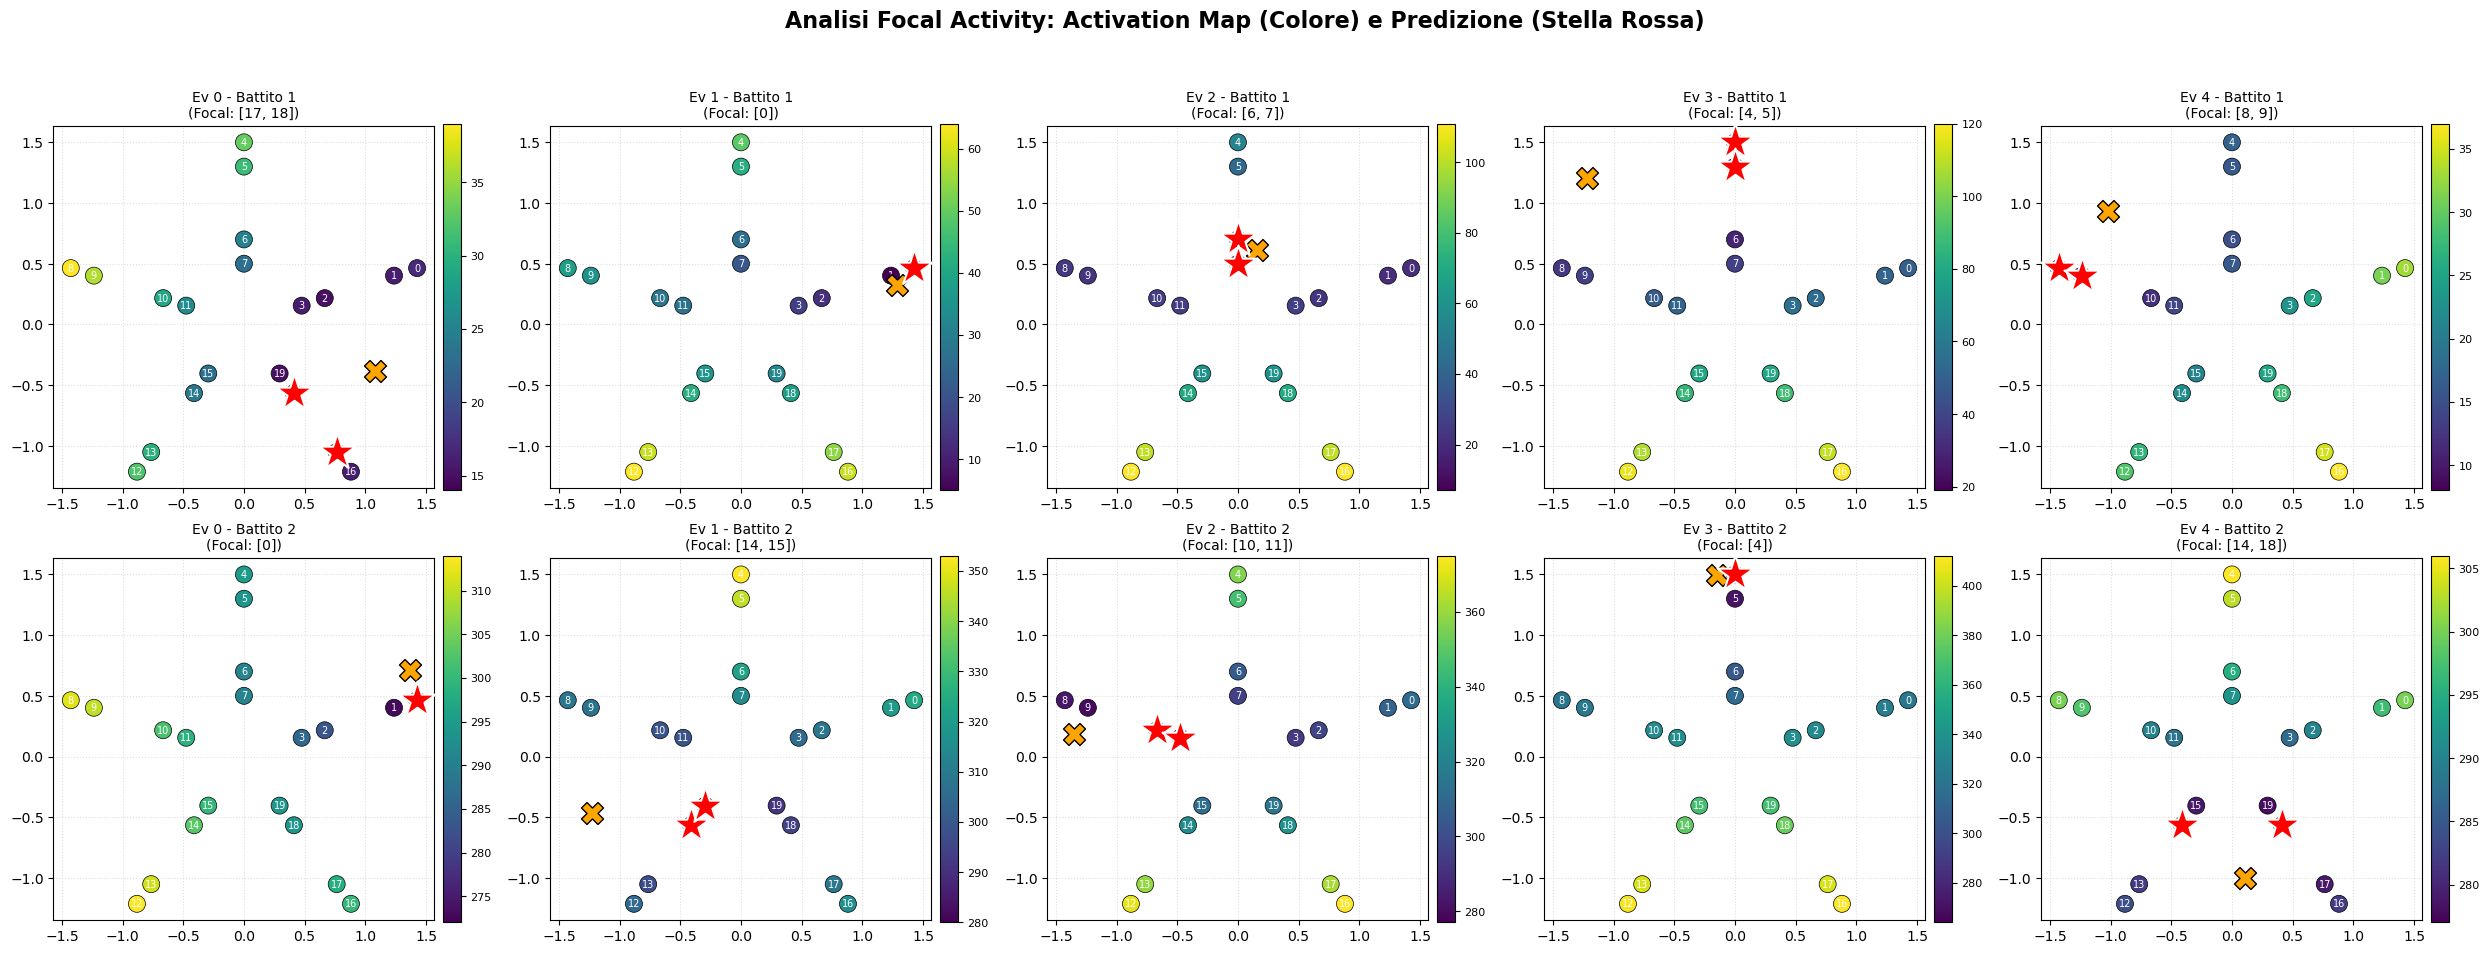

In [ ]:
# sensor_locs_raw = np.load('checkpoint1sensorlocations.npy')
# gt_focal = np.load('checkpoint1FocalPoints.npy')
# # Applichiamo la traslazione come richiesto
# sensor_locs = sensor_locs_raw - 2
# n_events = gt_focal.shape[0]

# # Creiamo una griglia: 2 righe (i battiti) x n_events (le colonne)
# fig, axes = plt.subplots(2, n_events, figsize=(5 * n_events, 10), squeeze=False)

# for ev in range(n_events):
#     # Recuperiamo il segnale dell'evento corrente (assumendo che 'signals_filtered' esista)
#     sig_ev = signals[ev, :, :]
    
#     # Chiamata alla tua funzione modificata
#     timings, LS = GroupSolutionCP1(sig_ev)
    
#     # Convertiamo in array numpy per poter usare l'indicizzazione avanzata [righe, colonne]
#     timings_arr = np.array(timings, dtype=float)
#     ls_arr = np.array(LS, dtype=float)

#     for beat_idx in range(2):
#         ax = axes[beat_idx, ev]
#         gp = gt_focal[ev, beat_idx] # Ground Truth (X Arancione)

#         # Prendiamo i tempi di attivazione per il battito corrente (tutti i sensori)
#         valori_colore = timings_arr[:, beat_idx]
        
#         # Maschera per escludere NaN o Inf che romperebbero il plot
#         mask_valid = np.isfinite(valori_colore)
        
#         if np.any(mask_valid):
#             # Coloriamo i pallini in base al tempo di attivazione (da viola a giallo)
#             sc = ax.scatter(
#                 sensor_locs[mask_valid, 0], sensor_locs[mask_valid, 1],
#                 c=valori_colore[mask_valid], cmap='viridis', 
#                 s=150, edgecolors='k', linewidths=0.5, zorder=2
#             )
#             # Aggiungiamo la barra del colore solo per chiarezza
#             cbar = plt.colorbar(sc, ax=ax, fraction=0.045, pad=0.02)
#             cbar.ax.tick_params(labelsize=8)
#         else:
#             # Fallback se non ci sono attivazioni valide
#             ax.scatter(sensor_locs[:, 0], sensor_locs[:, 1], c='lightgrey', s=80, alpha=0.3)

#         # --- 5. GROUND TRUTH (X ARANCIONE) ---
#         ax.scatter(gp[0], gp[1], marker='X', s=250, c='orange', 
#                    edgecolors='black', linewidths=1, zorder=5, label='GT')

#         # Cerchiamo gli indici dei sensori dove LS è > 0 (quindi sia 0.5 che 1.0)
#         pred_idx = np.where(ls_arr[:, beat_idx] > 0)[0] 
        
#         if len(pred_idx) > 0:
#             # Stampiamo una stella rossa gigante sopra il sensore predetto
#             ax.scatter(
#                 sensor_locs[pred_idx, 0], sensor_locs[pred_idx, 1],
#                 marker='*', s=750, c='red', edgecolors='white', 
#                 linewidths=1.5, zorder=10, label='PRED'
#             )
            
#             # Debug opzionale: stampa i sensori scelti nel titolo o console
#             # print(f"Ev {ev} Beat {beat_idx+1}: Sensori scelti {pred_idx}")

#         # Aggiungiamo i numeri dei sensori in piccolo per debugging
#         for i, (x, y) in enumerate(sensor_locs):
#             ax.text(x, y, str(i), fontsize=7, ha='center', va='center', color='white', zorder=3)

#         ax.set_aspect('equal')
#         ax.grid(True, linestyle=':', alpha=0.4)
#         ax.set_title(f'Ev {ev} - Battito {beat_idx+1}\n(Focal: {pred_idx.tolist()})', fontsize=10)

# # Titolo globale e layout
# plt.suptitle('Analisi Focal Activity: Activation Map (Colore) e Predizione (Stella Rossa)', 
#              fontsize=16, fontweight='bold', y=0.98)
# plt.tight_layout(rect=[0, 0.03, 1, 0.95])
# plt.show()

Event: 0
timings_event: [[17, 274], [16, 274], [16, 283], [16, 286], [32, 295], [30, 293], [25, 291], [23, 291], [38, 311], [36, 311], [29, 302], [26, 299], [32, 313], [30, 311], [24, 302], [22, 300], [16, 299], [16, 297], [14, 294], [16, 293]]
LS_event: [[0.0, 1.0], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.5, 0.0], [0.0, 0.0]]
--------------------
Event: 1
timings_event: [[8, 324], [5, 318], [13, 311], [16, 308], [47, 355], [41, 349], [25, 324], [22, 311], [38, 305], [35, 311], [29, 305], [27, 299], [66, 308], [60, 305], [41, 283], [38, 283], [60, 318], [54, 311], [41, 294], [33, 293]]
LS_event: [[0.5, 0.0], [0.5, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [0.0, 1.0], [0.0, 0.0], [0.0, 0.0], [0.0, 0.0], [

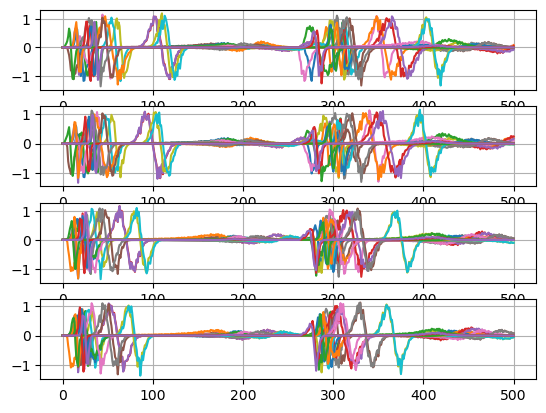

In [ ]:
# # loop su tutti gli eventi
# for ind_event in range(5):

#     # loop su tutte le spline
#     for ind_spline in range(5):

#         #plt.figure()

#         countEL = 1
#         for indS in np.arange(ind_spline*4, (ind_spline+1)*4, 1):

#             plt.subplot(4,1,countEL)
#             plt.plot(signals[ind_event, indS, :])
#             plt.grid(True)

#             countEL += 1

#         #plt.suptitle(f"Event {ind_event} - Spline {ind_spline}")
#         #plt.show()

#     # test della soluzione per l'evento
#     signals_event = signals[ind_event, :, :]
#     timings_event, LS_event = GroupSolutionCP1(signals_event)

#     print("Event:", ind_event)
#     print("timings_event:", timings_event)
#     print("LS_event:", LS_event)
#     print("--------------------")